# Play Analysis Pipeline

**Full pipeline:** Pre-snap YOLO detection → SAM3 tracking → Keypoint homography → Bird's-eye player cards

**Data:** TB2026 (Ravelin 2026)  
**Models:**
- Player detection: `yolo11m` fine-tuned (stage 4b @ 1280px)
- Field keypoints: `yolo11l-pose` upper-bound fold model (in-domain, 1280px)
- Tracking: SAM3 VOS


## 0. Setup

In [1]:
from pathlib import Path
import tempfile
import shutil
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import supervision as sv
from ultralytics import YOLO

from homography import (
    run_field_pose_model,
    project_to_field_yards,
    kpt_world, PX_PER_YARD,
)
from drawing import (
    create_football_field,
    draw_birdseye_cards,
    draw_keypoint_overlay,
    annotate,
    create_class_color_palette,
)
from sam3_tracking import run_sam3_tracking

In [2]:
# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_ROOT   = Path("../Data")
FRAMES_ROOT = DATA_ROOT / "Keypoints" / "frames" / "tb2026"
META_CSV    = DATA_ROOT / "metadata" / "tb2026_dataset_metadata.csv"

PLAYER_PT = Path("../Player_Detection/cross_stadium_results/4b_1280/train/weights/best.pt")

# ── Fold selection ────────────────────────────────────────────────────────────
# Each fold's model was trained on ~80% of TB2026 clips.
# Only run the pipeline on clips from the matching fold's val set (unseen data).
FOLD = 1

FOLD_MODEL = {
    0: Path("../Field_Keypoint_Detection/upper_bound_results/fold_0/train/weights/best.pt"),
    1: Path("../Field_Keypoint_Detection/upper_bound_results/fold_1/train/weights/best.pt"),
    2: Path("../Field_Keypoint_Detection/upper_bound_results/fold_2/train/weights/best.pt"),
    3: Path("../Field_Keypoint_Detection/upper_bound_results/fold_3/train/weights/best.pt"),
}

FOLD_CLIPS = {
    0: ["clip_008.mp4","clip_018.mp4","clip_024.mp4","clip_037.mp4","clip_043.mp4",
        "clip_044.mp4","clip_048.mp4","clip_056.mp4","clip_064.mp4","clip_069.mp4",
        "clip_078.mp4","clip_081.mp4","clip_082.mp4","clip_093.mp4","clip_094.mp4",
        "clip_101.mp4","clip_105.mp4","clip_107.mp4","clip_113.mp4","clip_135.mp4",
        "clip_144.mp4"],
    1: ["clip_013.mp4","clip_017.mp4","clip_019.mp4","clip_031.mp4","clip_041.mp4",
        "clip_055.mp4","clip_058.mp4","clip_059.mp4","clip_061.mp4","clip_065.mp4",
        "clip_079.mp4","clip_084.mp4","clip_087.mp4","clip_092.mp4","clip_095.mp4",
        "clip_100.mp4","clip_108.mp4","clip_114.mp4","clip_115.mp4","clip_133.mp4",
        "clip_141.mp4"],
    2: ["clip_009.mp4","clip_012.mp4","clip_016.mp4","clip_025.mp4","clip_028.mp4",
        "clip_032.mp4","clip_033.mp4","clip_034.mp4","clip_045.mp4","clip_047.mp4",
        "clip_050.mp4","clip_053.mp4","clip_054.mp4","clip_060.mp4","clip_068.mp4",
        "clip_088.mp4","clip_089.mp4","clip_097.mp4","clip_099.mp4","clip_121.mp4",
        "clip_128.mp4"],
    3: ["clip_007.mp4","clip_021.mp4","clip_029.mp4","clip_030.mp4","clip_035.mp4",
        "clip_057.mp4","clip_063.mp4","clip_070.mp4","clip_080.mp4","clip_098.mp4",
        "clip_103.mp4","clip_112.mp4","clip_117.mp4","clip_119.mp4","clip_120.mp4",
        "clip_122.mp4","clip_123.mp4","clip_127.mp4","clip_129.mp4","clip_134.mp4",
        "clip_137.mp4"],
}

KP_PT = FOLD_MODEL[FOLD]

OUTPUT_ROOT = Path("output")
OUTPUT_ROOT.mkdir(exist_ok=True)

# ── Inference settings ────────────────────────────────────────────────────────
PLAYER_CONF = 0.40
KP_DET_CONF = 0.25
KP_KPT_CONF = 0.30
IMGSZ       = 1280

In [3]:
# Load models
player_model = YOLO(str(PLAYER_PT))
kp_model     = YOLO(str(KP_PT))
YOLO_NAMES   = player_model.names
print("Player classes:", YOLO_NAMES)

# Load clip metadata
meta = pd.read_csv(META_CSV)
print(f"\n{len(meta)} clips available")
meta.head()

Player classes: {0: 'defense', 1: 'oline', 2: 'qb', 3: 'ref', 4: 'skill'}

107 clips available


,clip,play_num,start_frame,end_frame,n_frames,ODK,DN,DIST,HASH,YARD_LN,...,GN_LS,OFF_FORM,OFF_PLAY,OFF_STR,PLAY_DIR,GAP,PASS_ZONE,DEF_FRONT,COVERAGE,BLITZ
0,clip_007.mp4,7,0,39,40,O,1,10,R,42,...,27.0,TANK,NaN,R,R,C,NaN,NaN,NaN,NaN
1,clip_008.mp4,8,40,79,40,O,1,10,R,15,...,-1.0,TANK,NaN,R,R,C,NaN,NaN,NaN,NaN
2,clip_009.mp4,9,80,107,28,O,2,11,R,16,...,0.0,Doubles,NaN,BAL,R,NaN,NaN,NaN,NaN,NaN
3,clip_010.mp4,10,108,139,32,O,3,11,R,16,...,0.0,Doubles,NaN,BAL,R,NaN,NaN,NaN,NaN,NaN
4,clip_011.mp4,11,140,171,32,O,4,11,R,16,...,12.0,Doubles,NaN,L,L,NaN,NaN,NaN,NaN,NaN


## 1. Select a Play

Frames are stored as a flat sequence in `frames/tb2026/frame_XXXXXX.png`.
The metadata CSV maps each clip to its `start_frame` / `end_frame` indices.

fold_1 valid clips (21): ['clip_013.mp4', 'clip_017.mp4', 'clip_019.mp4', 'clip_031.mp4', 'clip_041.mp4', 'clip_055.mp4', 'clip_058.mp4', 'clip_059.mp4', 'clip_061.mp4', 'clip_065.mp4', 'clip_079.mp4', 'clip_084.mp4', 'clip_087.mp4', 'clip_092.mp4', 'clip_095.mp4', 'clip_100.mp4', 'clip_108.mp4', 'clip_114.mp4', 'clip_115.mp4', 'clip_133.mp4', 'clip_141.mp4']
Clip : clip_058.mp4
Play : DN=3  DIST=3  YARD_LN=11  TYPE=Run
Frames: 1148 → 1171  (24 frames)


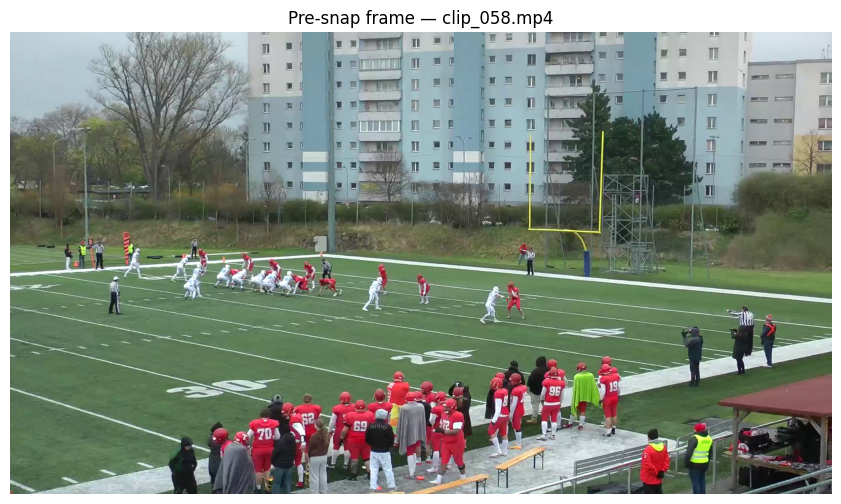

In [4]:
# Pick a clip from the selected fold's val set (model has not seen these)
valid_clips = FOLD_CLIPS[FOLD]
print(f"fold_{FOLD} valid clips ({len(valid_clips)}): {valid_clips}")

CLIP_NAME = "clip_058.mp4"   # must be in valid_clips above
assert CLIP_NAME in valid_clips, f"{CLIP_NAME} not in fold_{FOLD} val set!"

clip      = meta[meta["clip"] == CLIP_NAME].iloc[0]
start     = int(clip["start_frame"])
end       = int(clip["end_frame"])

frame_paths = [
    FRAMES_ROOT / f"frame_{i:06d}.png"
    for i in range(start, end + 1)
]

print(f"Clip : {CLIP_NAME}")
print(f"Play : DN={clip['DN']}  DIST={clip['DIST']}  YARD_LN={clip['YARD_LN']}  TYPE={clip['PLAY_TYPE']}")
print(f"Frames: {start} → {end}  ({len(frame_paths)} frames)")

presnap_path = frame_paths[0]
presnap      = np.array(Image.open(presnap_path).convert("RGB"))

plt.figure(figsize=(14, 6))
plt.imshow(presnap)
plt.title(f"Pre-snap frame — {CLIP_NAME}")
plt.axis("off")
plt.show()

## 2. Player Detection on Pre-Snap Frame

Detected 26 players
  skill       conf=0.87
  defense     conf=0.86
  skill       conf=0.84
  skill       conf=0.83
  defense     conf=0.80
  oline       conf=0.80
  defense     conf=0.80
  skill       conf=0.79
  defense     conf=0.79
  ref         conf=0.78
  defense     conf=0.77
  oline       conf=0.76
  skill       conf=0.76
  defense     conf=0.76
  oline       conf=0.76
  defense     conf=0.74
  ref         conf=0.73
  defense     conf=0.73
  oline       conf=0.73
  ref         conf=0.72
  qb          conf=0.67
  oline       conf=0.67
  defense     conf=0.66
  ref         conf=0.65
  defense     conf=0.63
  qb          conf=0.40


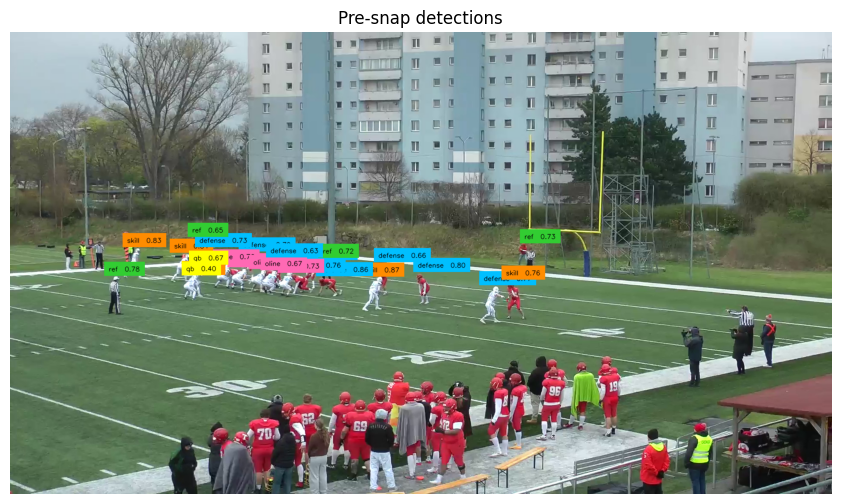

In [5]:
results = player_model(
    presnap, conf=PLAYER_CONF, imgsz=IMGSZ, verbose=False
)[0]

initial_detections = sv.Detections(
    xyxy=results.boxes.xyxy.cpu().numpy(),
    confidence=results.boxes.conf.cpu().numpy(),
    class_id=results.boxes.cls.cpu().numpy().astype(int),
)

print(f"Detected {len(initial_detections)} players")
for cls_id, conf in zip(initial_detections.class_id, initial_detections.confidence):
    print(f"  {YOLO_NAMES[cls_id]:<10}  conf={conf:.2f}")

palette           = create_class_color_palette(YOLO_NAMES)
labels            = [
    f"{YOLO_NAMES[c]}  {conf:.2f}"
    for c, conf in zip(initial_detections.class_id, initial_detections.confidence)
]
annotated_presnap = annotate(Image.fromarray(presnap), initial_detections, labels, palette)

plt.figure(figsize=(14, 6))
plt.imshow(annotated_presnap)
plt.title("Pre-snap detections")
plt.axis("off")
plt.show()

## 3. SAM3 Tracking Through the Play

SAM3 needs a directory of frames. We copy the clip frames to a temp folder,
run tracking, then clean up.

In [6]:
clip_output_dir = OUTPUT_ROOT / CLIP_NAME.replace(".mp4", "")
clip_output_dir.mkdir(exist_ok=True)

# Copy clip frames to a temp directory for SAM3
tmp_frames = Path(tempfile.mkdtemp())
for i, fp in enumerate(frame_paths):
    shutil.copy(fp, tmp_frames / f"frame_{i:06d}.png")

all_frame_detections, _ = run_sam3_tracking(
    source_dir=tmp_frames,
    output_dir=clip_output_dir,
    initial_detections=initial_detections,
    yolo_names=YOLO_NAMES,
)

shutil.rmtree(tmp_frames)   # cleanup
print(f"Tracked across {len(all_frame_detections)} frames")

Loading SAM-3 VOS Model on device: cuda...


Loading weights:   0%|          | 0/845 [00:00<?, ?it/s]

Initializing SAM-3 VOS tracking for 26 objects...



Starting VOS propagation across all frames...



Annotating 24 frames from VOS output...


✅ SAM-3 VOS Tracking Complete. Frames saved to: output/clip_058
Shutting down SAM-3 VOS resources...
Tracked across 24 frames


## 4. Keypoint Detection & Homography (per frame)

In [7]:
homographies   = {}   # frame_idx -> H or None
kpt_detections = {}   # frame_idx -> (62, 3) array

for i, fp in enumerate(frame_paths):
    frame_bgr = cv2.imread(str(fp))
    H, _ = run_field_pose_model(
        frame_bgr, kp_model,
        det_conf=KP_DET_CONF, kpt_conf=KP_KPT_CONF,
    )
    homographies[i] = H

    res = kp_model(frame_bgr, conf=KP_DET_CONF, verbose=False)[0]
    if res.keypoints is not None and len(res.keypoints.data) > 0:
        kpt_detections[i] = res.keypoints.data[0].cpu().numpy()

n_valid = sum(1 for H in homographies.values() if H is not None)
print(f"Valid homographies: {n_valid} / {len(frame_paths)} frames")

Valid homographies: 24 / 24 frames


### 4a. Keypoint overlay — sanity check on one frame

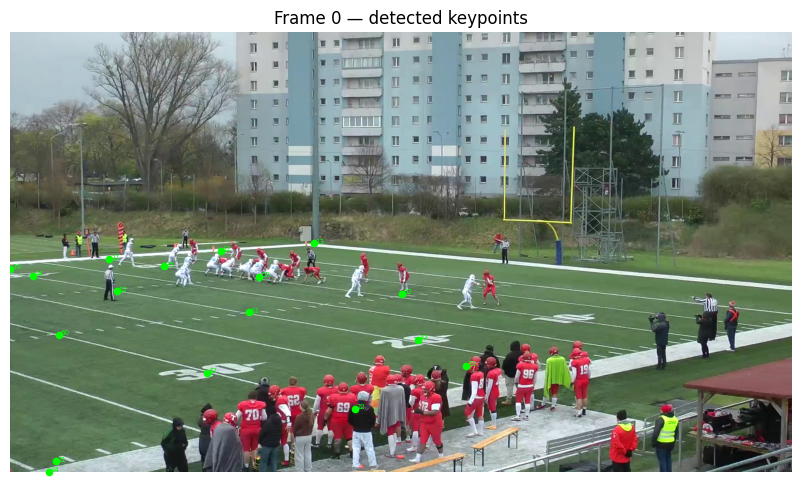

In [8]:
CHECK_FRAME = 0
frame_rgb   = cv2.cvtColor(cv2.imread(str(frame_paths[CHECK_FRAME])), cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(figsize=(14, 6))
ax.imshow(frame_rgb)
if CHECK_FRAME in kpt_detections:
    draw_keypoint_overlay(ax, kpt_detections[CHECK_FRAME], conf_thresh=KP_KPT_CONF)
ax.set_title(f"Frame {CHECK_FRAME} — detected keypoints")
ax.axis("off")
plt.show()

## 5. Bird's-Eye Player Cards

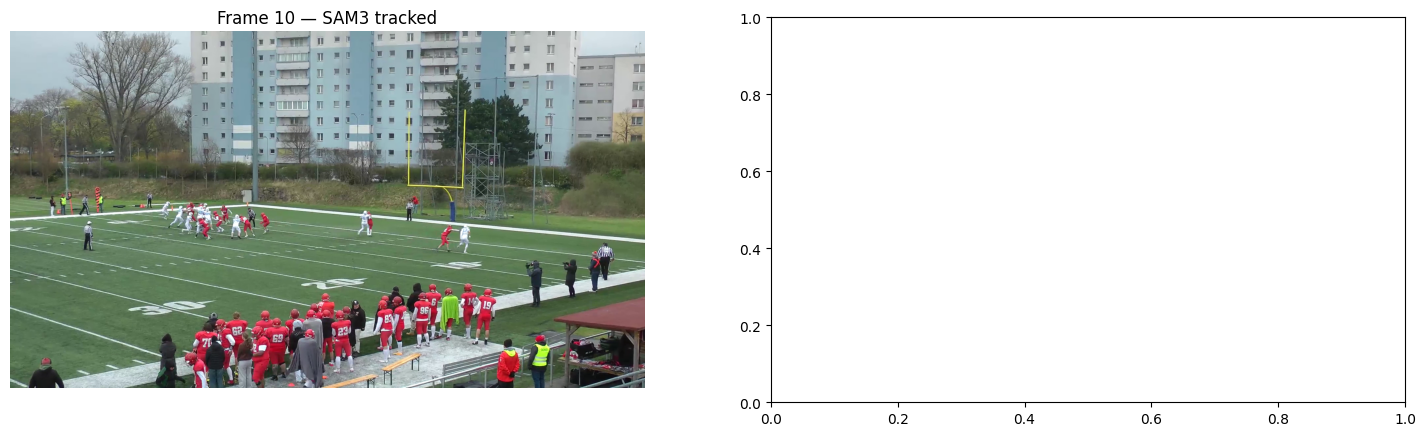

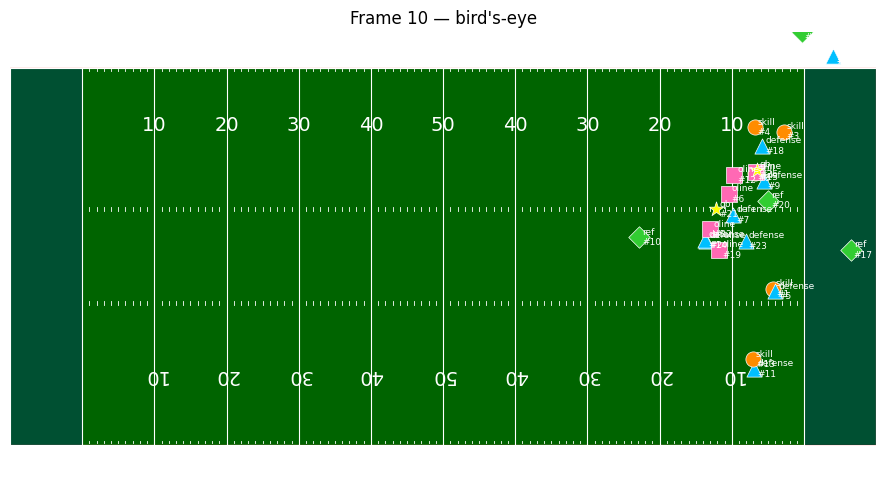

In [9]:
VIS_FRAME = 10

H    = homographies.get(VIS_FRAME)
dets = all_frame_detections.get(VIS_FRAME)

if H is None:
    print(f"No valid homography for frame {VIS_FRAME}")
elif dets is None or len(dets) == 0:
    print(f"No player detections for frame {VIS_FRAME}")
else:
    positions = project_to_field_yards(dets.xyxy, H)

    frame_rgb = cv2.cvtColor(cv2.imread(str(frame_paths[VIS_FRAME])), cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    axes[0].imshow(frame_rgb)
    axes[0].set_title(f"Frame {VIS_FRAME} — SAM3 tracked")
    axes[0].axis("off")

    _, ax_field = create_football_field(figsize=(9, 5))
    draw_birdseye_cards(
        ax_field, positions,
        class_ids=list(dets.class_id),
        yolo_names=YOLO_NAMES,
        player_ids=list(dets.tracker_id) if dets.tracker_id is not None else None,
    )
    ax_field.set_title(f"Frame {VIS_FRAME} — bird's-eye")
    plt.tight_layout()
    plt.show()

## 6. Reprojection Error Evaluation

For each frame, measure how well H maps detected keypoint positions to their
known field coordinates. Reports error in yards.

In [10]:
errors_per_frame = {}

for i, H in homographies.items():
    if H is None or i not in kpt_detections:
        continue

    kpts = kpt_detections[i]
    errs = []

    for idx, (x, y, conf) in enumerate(kpts):
        kpt_id = idx + 1
        if conf < KP_KPT_CONF or kpt_id not in kpt_world:
            continue
        pt_pred = cv2.perspectiveTransform(
            np.array([[[float(x), float(y)]]], dtype=np.float64), H
        )[0, 0]
        gt_x, gt_y = kpt_world[kpt_id]
        pt_gt = np.array([gt_x * PX_PER_YARD, gt_y * PX_PER_YARD])
        errs.append(np.linalg.norm(pt_pred - pt_gt) / PX_PER_YARD)

    if errs:
        errors_per_frame[i] = errs

all_errors = [e for errs in errors_per_frame.values() for e in errs]
print(f"Frames evaluated : {len(errors_per_frame)}")
print(f"Total keypoints  : {len(all_errors)}")
print(f"Mean error       : {np.mean(all_errors):.3f} yards")
print(f"Median error     : {np.median(all_errors):.3f} yards")
print(f"90th percentile  : {np.percentile(all_errors, 90):.3f} yards")

Frames evaluated : 24
Total keypoints  : 409
Mean error       : 2.413 yards
Median error     : 0.194 yards
90th percentile  : 2.940 yards


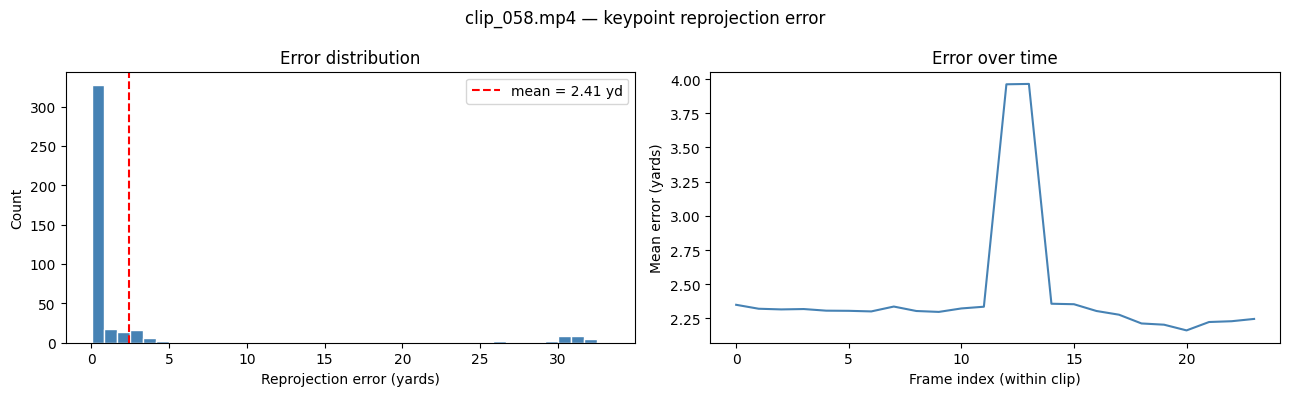

In [11]:
frame_means = [np.mean(e) for e in errors_per_frame.values()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(all_errors, bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(np.mean(all_errors), color="red", linestyle="--",
                label=f"mean = {np.mean(all_errors):.2f} yd")
axes[0].set_xlabel("Reprojection error (yards)")
axes[0].set_ylabel("Count")
axes[0].set_title("Error distribution")
axes[0].legend()

axes[1].plot(list(errors_per_frame.keys()), frame_means, color="steelblue", linewidth=1.5)
axes[1].set_xlabel("Frame index (within clip)")
axes[1].set_ylabel("Mean error (yards)")
axes[1].set_title("Error over time")

plt.suptitle(f"{CLIP_NAME} — keypoint reprojection error")
plt.tight_layout()
plt.show()

## 7. Play Analysis — Formation, Yard-Line/Hash, Play-Type

Runs the three rule-based classifiers from `Play_Analysis/` on this clip's own detections, tracking, and homography above -- the same self-detected inputs used for the thesis's RQ3 self-detected-ablation numbers, chained live here instead of via separate offline scripts.

In [12]:
import sys
sys.path.insert(0, str(Path("../Play_Analysis").resolve()))

from classify_formation import classify_formation, CLASS_OLINE, CLASS_QB, CLASS_SKILL
from yard_hash_analysis import classify_yardline, classify_hash, attack_direction, CLASS_DEFENSE
from play_type_classification import (
    classify_play_type, fit_slope, _clean_slope, _valid_indices,
    GT_QB_THRESH, GT_OLINE_THRESH, FPS,
)


def positions_for(dets, H, class_id):
    idx = _valid_indices(dets.xyxy, dets.class_id == class_id)
    return project_to_field_yards(dets.xyxy[idx], H) if len(idx) > 0 else []


### 7a. Formation & Yard-Line/Hash (presnap frame)

In [13]:
PRESNAP_FRAME = 0
H0    = homographies.get(PRESNAP_FRAME)
dets0 = all_frame_detections.get(PRESNAP_FRAME)

if H0 is None or dets0 is None:
    print("No valid homography/detections for the presnap frame -- cannot classify.")
else:
    skill_pos   = positions_for(dets0, H0, CLASS_SKILL)
    oline_pos   = positions_for(dets0, H0, CLASS_OLINE)
    defense_pos = positions_for(dets0, H0, CLASS_DEFENSE)

    formation = classify_formation(skill_pos, oline_pos)
    yard_line = classify_yardline(oline_pos, defense_pos)
    hash_mark = classify_hash(oline_pos, defense_pos)

    print(f"Formation : {formation:<8}  (true: {clip['OFF_FORM']})")
    if yard_line is not None:
        print(f"Yard line : {yard_line:+.1f}  (true: {clip['YARD_LN']:+.0f})")
    else:
        print("Yard line : undetermined")
    print(f"Hash      : {hash_mark}       (true: {clip['HASH']})")


Formation : Doubles   (true: Doubles)
Yard line : +10.4  (true: +11)
Hash      : L       (true: L)


### 7b. Play-Type (QB dropback / Oline drive over the whole clip)

In [14]:
qb_traj, oline_traj = [], []
for i in sorted(all_frame_detections.keys()):
    H    = homographies.get(i)
    dets = all_frame_detections.get(i)
    if H is None or dets is None:
        continue
    qb_pos_i = positions_for(dets, H, CLASS_QB)
    if qb_pos_i:
        qb_traj.append((i, float(np.mean([p[0] for p in qb_pos_i]))))
    oline_pos_i = positions_for(dets, H, CLASS_OLINE)
    if oline_pos_i:
        oline_traj.append((i, float(np.median([p[0] for p in oline_pos_i]))))

direction = attack_direction(oline_pos, defense_pos)  # from the presnap frame, cell 7a

if direction is None:
    print("Attack direction undetermined -- cannot classify play type.")
else:
    sign = 1.0 if direction == "inc" else -1.0
    qb_slope    = fit_slope(qb_traj)
    oline_slope = fit_slope(oline_traj)
    qb_slope_yd_s    = _clean_slope(sign * qb_slope * FPS) if qb_slope is not None else None
    oline_slope_yd_s = _clean_slope(sign * oline_slope * FPS) if oline_slope is not None else None

    play_type = classify_play_type(qb_slope_yd_s, oline_slope_yd_s, GT_QB_THRESH, GT_OLINE_THRESH)

    print(f"QB slope    : {qb_slope_yd_s:+.2f} yd/s" if qb_slope_yd_s is not None else "QB slope    : n/a")
    print(f"Oline slope : {oline_slope_yd_s:+.2f} yd/s" if oline_slope_yd_s is not None else "Oline slope : n/a")
    print(f"Play type   : {play_type}   (true: {clip['PLAY_TYPE']})")


QB slope    : +2.12 yd/s
Oline slope : +0.54 yd/s
Play type   : Run   (true: Run)
